## 12. Autovalores e autovetores

Em muitas áreas aparecem problemas com várias grandezas relacionadas entre si — correntes nas malhas de um circuito, posições de massas ligadas por molas, quantidades de sal em tanques interligados — cujos modelos são sistemas de EDOs de 1ª ordem (Boyce e DiPrima, 2020). Nos Notebooks 10 e 11 escrevemos e desenhamos esses sistemas; no Exemplo 10.5, o `sp.dsolve` deu a solução geral

$$
\mathbf{y}=c_1\begin{bmatrix}1\\1\end{bmatrix}e^{-2t}+c_2\begin{bmatrix}1\\-1\end{bmatrix}e^{-4t}
\quad\text{para}\quad
\mathbf{y}'=\begin{bmatrix}-3&1\\1&-3\end{bmatrix}\mathbf{y},
$$

e comentamos que os números $-2$ e $-4$ e os vetores $(1,1)$ e $(1,-1)$ são os **autovalores** e **autovetores** da matriz do sistema.

Neste notebook vamos entender de onde vêm esses números e vetores, como calculá-los com o SymPy e o NumPy, e o que eles significam geometricamente. Numa seção opcional, no fim, veremos também como calcular numericamente o maior autovalor de uma matriz pelo **método da potência**. No Notebook 13 eles serão usados para montar a solução geral de sistemas lineares, e no Notebook 14 para classificar pontos críticos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
sp.init_printing()

### 12.1 Do sistema de EDOs ao problema de autovalor

Considere um sistema linear homogêneo com coeficientes constantes,

$$
\mathbf{y}'=\mathbf{A}\mathbf{y}.
$$

Inspirados no caso de uma única equação, $y'=ay$, cuja solução é $y=ce^{at}$, vamos procurar soluções da forma $\mathbf{y}=\mathbf{v}e^{\lambda t}$, com $\mathbf{v}$ um vetor constante. Substituindo no sistema, obtemos

$$
\mathbf{y}'=\lambda\mathbf{v}e^{\lambda t}=\mathbf{A}\mathbf{v}e^{\lambda t}.
$$

Dividindo por $e^{\lambda t}\neq0$, chegamos ao **problema de autovalor**

$$
\mathbf{A}\mathbf{v}=\lambda\mathbf{v}.
$$

Um número $\lambda$ para o qual essa equação tem solução $\mathbf{v}\neq\mathbf{0}$ é um **autovalor** de $\mathbf{A}$, e cada tal $\mathbf{v}$ é um **autovetor** associado a $\lambda$. Portanto, $\mathbf{y}=\mathbf{v}e^{\lambda t}$ é uma solução não trivial do sistema exatamente quando $\lambda$ é um autovalor de $\mathbf{A}$ e $\mathbf{v}$ um autovetor associado.

Note que, se $\mathbf{v}$ é autovetor, qualquer múltiplo $c\mathbf{v}$ ($c\neq0$) também é: $\mathbf{A}(c\mathbf{v})=c\mathbf{A}\mathbf{v}=\lambda(c\mathbf{v})$. Por isso um autovetor é determinado apenas **a menos de um fator**, e diferentes programas (ou diferentes pessoas) podem apresentar autovetores diferentes para o mesmo autovalor — todos múltiplos uns dos outros.

**Exemplo 12.1:** Verificar que $(1,1)$ e $(1,-1)$ são autovetores da matriz do Exemplo 10.5, associados aos autovalores $-2$ e $-4$, e que $(1,0)$ não é autovetor.

*Solução:* basta calcular $\mathbf{A}\mathbf{v}$ e comparar com $\lambda\mathbf{v}$.

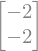

True

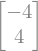

True

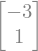

In [2]:
A = sp.Matrix([[-3, 1], [1, -3]])
v1 = sp.Matrix([1, 1])
v2 = sp.Matrix([1, -1])
u = sp.Matrix([1, 0])

display(A*v1, A*v1 == -2*v1)
display(A*v2, A*v2 == -4*v2)
display(A*u)

De fato, $\mathbf{A}(1,1)^T=(-2,-2)^T=-2\,(1,1)^T$ e $\mathbf{A}(1,-1)^T=(-4,4)^T=-4\,(1,-1)^T$. Já $\mathbf{A}(1,0)^T=(-3,1)^T$ não é múltiplo de $(1,0)^T$, então $(1,0)$ não é autovetor. (Aqui a comparação com `==` funciona porque as matrizes contêm só números inteiros; com expressões simbólicas, use o resíduo simplificado, como no Exemplo 10.1.)

### 12.2 Interpretação geométrica

A equação $\mathbf{A}\mathbf{v}=\lambda\mathbf{v}$ diz que a matriz $\mathbf{A}$ transforma o autovetor $\mathbf{v}$ num vetor **paralelo** a ele: $\mathbf{A}$ apenas estica ($|\lambda|>1$), encolhe ($|\lambda|<1$) e/ou inverte o sentido ($\lambda<0$) de $\mathbf{v}$, sem girá-lo. Para um vetor qualquer, $\mathbf{A}\mathbf{u}$ em geral aponta numa direção diferente da de $\mathbf{u}$.

Isso tem uma consequência direta no campo de direções de $\mathbf{y}'=\mathbf{A}\mathbf{y}$ (Notebooks 10 e 11): sobre a reta que passa pela origem na direção de um autovetor real, o campo $\mathbf{A}\mathbf{y}=\lambda\mathbf{y}$ é **paralelo à própria reta**. Uma solução que começa sobre essa reta permanece nela, e é exatamente a solução $\mathbf{y}=c\,\mathbf{v}e^{\lambda t}$: ela se afasta da origem se $\lambda>0$ e se aproxima dela se $\lambda<0$.

**Exemplo 12.2:** Desenhar, para a matriz do Exemplo 12.1, os vetores $\mathbf{v}_1=(1,1)$ e $\mathbf{u}=(1,0)$ junto com suas imagens $\mathbf{A}\mathbf{v}_1$ e $\mathbf{A}\mathbf{u}$ e, ao lado, o campo de direções de $\mathbf{y}'=\mathbf{A}\mathbf{y}$ com as retas dos dois autovetores.

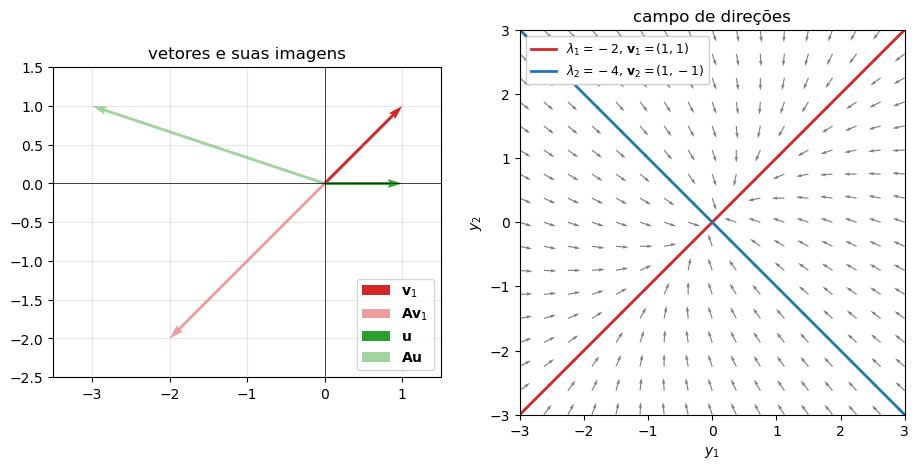

In [3]:
A = np.array([[-3, 1], [1, -3]])
v1, v2, u = np.array([1, 1]), np.array([1, -1]), np.array([1, 0])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

# à esquerda: os vetores e suas imagens por A
for vec, cor, nome in [(v1, 'tab:red', r'\mathbf{v}_1'), (u, 'tab:green', r'\mathbf{u}')]:
    Av = A @ vec
    ax1.quiver(0, 0, *vec, angles='xy', scale_units='xy', scale=1, color=cor, label=f'${nome}$')
    ax1.quiver(0, 0, *Av, angles='xy', scale_units='xy', scale=1, color=cor, alpha=0.45,
               label=f'$\\mathbf{{A}}{nome}$')
ax1.set_xlim(-3.5, 1.5); ax1.set_ylim(-2.5, 1.5); ax1.set_aspect('equal')
ax1.axhline(0, color='k', lw=0.5); ax1.axvline(0, color='k', lw=0.5)
ax1.grid(alpha=0.3); ax1.legend(loc='lower right'); ax1.set_title('vetores e suas imagens')

# à direita: campo de direções (setas normalizadas) e as retas dos autovetores
Y1, Y2 = np.meshgrid(np.linspace(-3, 3, 17), np.linspace(-3, 3, 17))
V1 = A[0, 0]*Y1 + A[0, 1]*Y2
V2 = A[1, 0]*Y1 + A[1, 1]*Y2
N = np.hypot(V1, V2)
N[N == 0] = 1
ax2.quiver(Y1, Y2, V1/N, V2/N, color='gray', width=0.003)
s = np.array([-5, 5])
ax2.plot(s*v1[0], s*v1[1], color='tab:red', lw=2, label=r'$\lambda_1=-2$, $\mathbf{v}_1=(1,1)$')
ax2.plot(s*v2[0], s*v2[1], color='tab:blue', lw=2, label=r'$\lambda_2=-4$, $\mathbf{v}_2=(1,-1)$')
ax2.set_xlim(-3, 3); ax2.set_ylim(-3, 3); ax2.set_aspect('equal')
ax2.set_xlabel('$y_1$'); ax2.set_ylabel('$y_2$')
ax2.legend(loc='upper left', fontsize=9, framealpha=1); ax2.set_title('campo de direções')
plt.show()

À esquerda, $\mathbf{A}\mathbf{v}_1=-2\mathbf{v}_1$ tem a mesma direção de $\mathbf{v}_1$ (com o sentido invertido e o dobro do comprimento), enquanto $\mathbf{A}\mathbf{u}=(-3,1)$ aponta numa direção diferente da de $\mathbf{u}$. À direita, sobre as duas retas as setas do campo são paralelas às retas e apontam para a origem (os dois autovalores são negativos) — compare com o retrato de fase do Exemplo 11.1, em que as trajetórias chegam à origem tangentes à reta $y_2=y_1$.

### 12.3 Cálculo de autovalores e autovetores

A equação $\mathbf{A}\mathbf{v}=\lambda\mathbf{v}$ pode ser reescrita como

$$
(\mathbf{A}-\lambda\mathbf{I})\mathbf{v}=\mathbf{0}.
$$

É um sistema linear homogêneo, que tem soluções não nulas se, e somente se, a matriz $\mathbf{A}-\lambda\mathbf{I}$ for singular, isto é,

$$
\det(\mathbf{A}-\lambda\mathbf{I})=0.
$$

Para uma matriz $n\times n$, essa é uma equação polinomial de grau $n$ em $\lambda$, chamada **equação característica** de $\mathbf{A}$; o polinômio é o **polinômio característico**. Os autovalores são as suas raízes — reais ou complexas. Para cada autovalor $\lambda$, os autovetores associados são as soluções não nulas de $(\mathbf{A}-\lambda\mathbf{I})\mathbf{v}=\mathbf{0}$, ou seja, os vetores não nulos do **núcleo** (espaço nulo) de $\mathbf{A}-\lambda\mathbf{I}$.

**Exemplo 12.3:** Encontre os autovalores e autovetores da matriz
$$
\mathbf{A}=\begin{bmatrix}3&-1\\4&-2\end{bmatrix}.
$$

*Solução:* primeiro, passo a passo. Montamos e resolvemos a equação característica:

In [4]:
lamb = sp.symbols('lambda')
A = sp.Matrix([[3, -1], [4, -2]])
I = sp.eye(2)

eq = sp.Eq((A - lamb*I).det(), 0)
display(eq)
autovalores = sp.solve(eq, lamb)
autovalores

Os autovalores são $\lambda_1=-1$ e $\lambda_2=2$. Para cada um, resolvemos o sistema $(\mathbf{A}-\lambda\mathbf{I})\mathbf{v}=\mathbf{0}$:

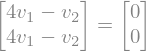

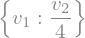

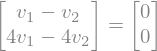

In [5]:
v1, v2 = sp.symbols('v_1 v_2')
v = sp.Matrix([v1, v2])
for lam in autovalores:
    M = A - lam*I
    display(sp.Eq(M*v, sp.zeros(2, 1)), sp.solve(M*v, [v1, v2]))

Para $\lambda_1=-1$ as duas equações se reduzem a $4v_1-v_2=0$, ou seja, $v_2=4v_1$; para $\lambda_2=2$, a $v_1-v_2=0$, ou seja, $v_2=v_1$. O sistema tem infinitas soluções (uma variável livre), como esperado: o autovetor é determinado a menos de um fator. Escolhendo $v_1=1$, obtemos

$$
\mathbf{v}_1=\begin{bmatrix}1\\4\end{bmatrix}\ \text{ para }\ \lambda_1=-1,
\qquad
\mathbf{v}_2=\begin{bmatrix}1\\1\end{bmatrix}\ \text{ para }\ \lambda_2=2.
$$

O mesmo resultado pode ser obtido diretamente com o método `nullspace()`, que devolve uma base do núcleo de uma matriz:

In [6]:
for lam in autovalores:
    print(f'λ = {lam}:  base do núcleo de A - λI =', [list(w) for w in (A - lam*I).nullspace()])

λ = -1:  base do núcleo de A - λI = [[1/4, 1]]
λ = 2:  base do núcleo de A - λI = [[1, 1]]


Na prática, o SymPy faz tudo isso de uma vez. O método `eigenvals()` devolve um dicionário `{autovalor: multiplicidade}`, e o `eigenvects()` uma lista de tuplas `(autovalor, multiplicidade, [autovetores])`:

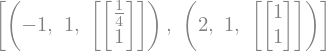

In [7]:
display(A.eigenvals())
display(A.eigenvects())

O SymPy apresenta o autovetor de $\lambda_1=-1$ como $(1/4,\ 1)$, que é $(1,4)$ dividido por 4 — o mesmo autovetor, a menos de um fator.

#### Atividade 12.1

Encontre, passo a passo como no Exemplo 12.3, os autovalores e os autovetores da matriz $\mathbf{A}=\begin{bmatrix}5&-1\\3&1\end{bmatrix}$. Confira o resultado com `eigenvects()` e verifique que $\mathbf{A}\mathbf{v}=\lambda\mathbf{v}$ para cada par encontrado.

#### 12.3.1 Traço e determinante

Para uma matriz $2\times2$ qualquer, $\mathbf{A}=\begin{bmatrix}a&b\\c&d\end{bmatrix}$, o polinômio característico pode ser escrito em termos de duas quantidades da matriz: o **traço** $\operatorname{tr}\mathbf{A}=a+d$ (soma da diagonal) e o **determinante** $\det\mathbf{A}=ad-bc$:

In [8]:
a, b, c, d = sp.symbols('a b c d')
M = sp.Matrix([[a, b], [c, d]])
p = sp.expand((M - lamb*sp.eye(2)).det())
display(p)
display(sp.expand(p - (lamb**2 - M.trace()*lamb + M.det())))   # dá zero

Ou seja,

$$
\det(\mathbf{A}-\lambda\mathbf{I})=\lambda^2-(\operatorname{tr}\mathbf{A})\,\lambda+\det\mathbf{A}.
$$

Como esse polinômio também é igual a $(\lambda-\lambda_1)(\lambda-\lambda_2)=\lambda^2-(\lambda_1+\lambda_2)\lambda+\lambda_1\lambda_2$, concluímos que

$$
\lambda_1+\lambda_2=\operatorname{tr}\mathbf{A},\qquad \lambda_1\lambda_2=\det\mathbf{A}.
$$

No Exemplo 12.3, $\operatorname{tr}\mathbf{A}=3-2=1=-1+2$ e $\det\mathbf{A}=-6+4=-2=(-1)\cdot2$. As duas relações valem para matrizes $n\times n$ de qualquer tamanho (a soma dos $n$ autovalores, contados com multiplicidade, é o traço e o produto é o determinante). Elas serão a base dos critérios de estabilidade do Notebook 14, que permitem saber, por exemplo, se os dois autovalores têm o mesmo sinal ($\det\mathbf{A}>0$) sem calculá-los.

In [9]:
print('traço =', A.trace(), '   soma dos autovalores =', sum(autovalores))
print('det   =', A.det(), '   produto dos autovalores =', sp.prod(autovalores))

traço = 1    soma dos autovalores = 1
det   = -2    produto dos autovalores = -2


### 12.4 Multiplicidade algébrica e geométrica

Quando a equação característica tem raízes repetidas, é preciso distinguir duas noções de multiplicidade de um autovalor $\lambda$:

- **multiplicidade algébrica** $m$: o número de vezes que $\lambda$ aparece como raiz da equação característica;
- **multiplicidade geométrica** $q$: o número de autovetores **linearmente independentes** associados a $\lambda$, isto é, a dimensão do núcleo de $\mathbf{A}-\lambda\mathbf{I}$.

Sempre vale $1\le q\le m$. Quando $q<m$ para algum autovalor, a matriz não tem $n$ autovetores linearmente independentes; veremos no Notebook 13 que esse caso exige um cuidado especial na montagem da solução geral do sistema de EDOs.

**Exemplo 12.4:** Encontre a equação característica, os autovalores e os autovetores da matriz
$$
\mathbf{A}=\begin{bmatrix}0&1&1\\1&0&1\\1&1&0\end{bmatrix}.
$$

In [10]:
A = sp.Matrix([[0, 1, 1], [1, 0, 1], [1, 1, 0]])
p = (A - lamb*sp.eye(3)).det()
display(sp.Eq(sp.factor(p), 0))
for val, m, vetores in A.eigenvects():
    print(f'λ = {val}:  mult. algébrica = {m},  mult. geométrica = {len(vetores)},  autovetores:',
          [list(w) for w in vetores])

λ = -1:  mult. algébrica = 2,  mult. geométrica = 2,  autovetores: [[-1, 1, 0], [-1, 0, 1]]
λ = 2:  mult. algébrica = 1,  mult. geométrica = 1,  autovetores: [[1, 1, 1]]


A equação característica é $-(\lambda-2)(\lambda+1)^2=0$: há apenas dois autovalores distintos. O autovalor $\lambda_1=-1$ tem multiplicidade algébrica 2 e, como $\mathbf{A}+\mathbf{I}$ é a matriz com todos os elementos iguais a 1 (de posto 1), o seu núcleo tem dimensão $3-1=2$: há **dois** autovetores independentes, $(-1,1,0)$ e $(-1,0,1)$ — multiplicidade geométrica 2. Qualquer combinação deles (não nula) também é autovetor de $\lambda_1$. O autovalor $\lambda_2=2$ é simples, com autovetor $(1,1,1)$. Ao todo, a matriz tem 3 autovetores linearmente independentes.

Confira também as relações da Seção 12.3.1: $(-1)+(-1)+2=0=\operatorname{tr}\mathbf{A}$ e $(-1)(-1)(2)=2=\det\mathbf{A}$.

**Exemplo 12.5:** (Boyce e DiPrima, 2020) Encontre os autovalores e autovetores da matriz
$$
\mathbf{A}=\begin{bmatrix}1&-1\\1&3\end{bmatrix}.
$$

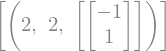

dimensão do núcleo de A - 2I: 1


In [11]:
A = sp.Matrix([[1, -1], [1, 3]])
display(sp.factor(A.charpoly(lamb).as_expr()))
display(A.eigenvects())
print('dimensão do núcleo de A - 2I:', len((A - 2*sp.eye(2)).nullspace()))

Agora o autovalor $\lambda=2$ tem multiplicidade algébrica 2, mas a matriz $\mathbf{A}-2\mathbf{I}=\begin{bmatrix}-1&-1\\1&1\end{bmatrix}$ tem posto 1, e o núcleo só contém os múltiplos de $(-1,1)$: multiplicidade geométrica 1. Essa matriz tem apenas **um** autovetor independente — não é possível escolher dois autovetores linearmente independentes. O sistema $\mathbf{y}'=\mathbf{A}\mathbf{y}$ correspondente será resolvido no Notebook 13.

#### Atividade 12.2

Determine os autovalores da matriz $\mathbf{A}=\begin{bmatrix}1&1&0\\-1&3&0\\1&0&2\end{bmatrix}$ e as suas multiplicidades algébrica e geométrica. Quantos autovetores linearmente independentes essa matriz tem?

### 12.5 Autovalores complexos

Mesmo quando todos os elementos de $\mathbf{A}$ são reais, as raízes da equação característica podem ser complexas. Nesse caso elas aparecem em **pares conjugados** $\lambda=\alpha\pm i\beta$ (pois os coeficientes do polinômio são reais), e os autovetores associados também são complexos conjugados: se $\mathbf{A}\mathbf{v}=\lambda\mathbf{v}$, conjugando os dois lados obtemos $\mathbf{A}\bar{\mathbf{v}}=\bar\lambda\bar{\mathbf{v}}$.

**Exemplo 12.6:** (Boyce e DiPrima, 2020) Encontre os autovalores e autovetores da matriz
$$
\mathbf{A}=\begin{bmatrix}-\frac12&1\\-1&-\frac12\end{bmatrix}.
$$

*Solução:* usamos `sp.Rational` para que o SymPy trabalhe com frações exatas (com `-1/2` o Python criaria o número de ponto flutuante `-0.5`).

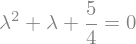

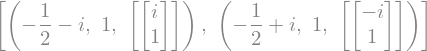

In [12]:
A = sp.Matrix([[-sp.Rational(1, 2), 1], [-1, -sp.Rational(1, 2)]])
display(sp.Eq(sp.expand((A - lamb*sp.eye(2)).det()), 0))
display(A.eigenvects())

A equação característica $\lambda^2+\lambda+\frac54=0$ tem discriminante negativo e raízes $\lambda=-\frac12\pm i$. Os autovetores, $(\mp i,\ 1)$, são complexos conjugados, como esperado. Em particular, não há nenhum autovetor **real**: nenhuma reta pela origem é levada por $\mathbf{A}$ em si mesma. No campo de direções isso aparece como a ausência de retas invariantes — as setas giram em torno da origem:

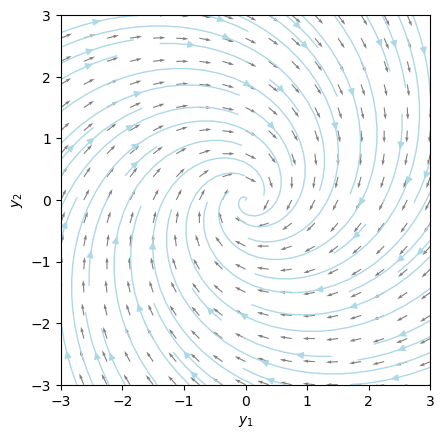

In [13]:
An = np.array(A, dtype=float)
Y1, Y2 = np.meshgrid(np.linspace(-3, 3, 17), np.linspace(-3, 3, 17))
V1 = An[0, 0]*Y1 + An[0, 1]*Y2
V2 = An[1, 0]*Y1 + An[1, 1]*Y2
N = np.hypot(V1, V2)
N[N == 0] = 1
plt.quiver(Y1, Y2, V1/N, V2/N, color='gray', width=0.003)
plt.streamplot(Y1, Y2, V1, V2, color='lightblue', density=0.8, linewidth=1)
plt.gca().set_aspect('equal')
plt.xlabel('$y_1$'); plt.ylabel('$y_2$')
plt.show()

É o mesmo padrão de rotação dos pontos espirais e centros do Notebook 11. A parte real $\alpha=-\frac12$ e a parte imaginária $\beta=1$ dos autovalores vão determinar, no Notebook 13, a taxa de decaimento ($e^{-t/2}$) e a frequência de rotação das soluções.

#### Atividade 12.3

Encontre os autovalores e os autovetores da matriz $\mathbf{A}=\begin{bmatrix}0&-2\\1&2\end{bmatrix}$. Verifique que o conjugado do autovetor associado a $\lambda$ é autovetor associado a $\bar\lambda$ e confira as relações $\lambda_1+\lambda_2=\operatorname{tr}\mathbf{A}$ e $\lambda_1\lambda_2=\det\mathbf{A}$.

### 12.6 Autovalores e autovetores com NumPy

O SymPy calcula autovalores de forma **exata**, resolvendo a equação característica. Isso só é viável para matrizes pequenas: não existe fórmula para as raízes de polinômios de grau 5 ou mais, e mesmo para graus 3 e 4 as expressões exatas ficam enormes. Na prática, autovalores são calculados por métodos **numéricos** iterativos, como o que está por trás da função `np.linalg.eig` do NumPy (e o método da potência da próxima seção, opcional, o mais simples deles).

A função `np.linalg.eig(A)` devolve dois arrays: o vetor `w` com os autovalores e a matriz `V` cujas **colunas** são autovetores **normalizados** (de norma 1), na mesma ordem dos autovalores.

**Exemplo 12.7:** Calcular com NumPy os autovalores e autovetores da matriz do Exemplo 12.3 e comparar com o resultado do SymPy.

In [14]:
A = np.array([[3, -1], [4, -2]])
w, V = np.linalg.eig(A)
print('autovalores:', w)
print('V =\n', V)

for k in range(len(w)):
    print(f'λ = {w[k]: .4f}:  coluna V[:, {k}] = {V[:, k]},  A v - λ v = {A @ V[:, k] - w[k]*V[:, k]}')

autovalores: [ 2. -1.]
V =
 [[0.70710678 0.24253563]
 [0.70710678 0.9701425 ]]
λ =  2.0000:  coluna V[:, 0] = [0.70710678 0.70710678],  A v - λ v = [0. 0.]
λ = -1.0000:  coluna V[:, 1] = [0.24253563 0.9701425 ],  A v - λ v = [3.33066907e-16 3.33066907e-16]


A coluna associada a $\lambda=-1$ é $(0{,}2425;\ 0{,}9701)$, que é o autovetor $(1,4)$ do Exemplo 12.3 dividido pela sua norma $\sqrt{17}$; a associada a $\lambda=2$ é $(1,1)/\sqrt2$. Cuidado para não ler as **linhas** de `V` como autovetores.

As $n$ igualdades $\mathbf{A}\mathbf{v}_k=\lambda_k\mathbf{v}_k$ podem ser escritas de uma vez como $\mathbf{A}\mathbf{V}=\mathbf{V}\boldsymbol{\Lambda}$, com $\boldsymbol{\Lambda}$ a matriz diagonal dos autovalores:

In [15]:
print(np.allclose(A @ V, V @ np.diag(w)))

True


Por serem calculados em ponto flutuante, os resultados do NumPy carregam erros de arredondamento. Isso é especialmente visível com autovalores repetidos. Para a matriz do Exemplo 12.5, que tem o autovalor exato $\lambda=2$ (duplo) e um só autovetor independente:

In [16]:
w, V = np.linalg.eig(np.array([[1, -1], [1, 3]]))
print('autovalores:', w)
print('V =\n', V)

autovalores: [2.00000002 1.99999998]
V =
 [[-0.70710677 -0.70710679]
 [ 0.70710679  0.70710677]]


O NumPy devolve dois autovalores **ligeiramente** diferentes de 2 (diferença da ordem de $10^{-8}$) e duas colunas praticamente paralelas a $(-1,1)$ — a forma numérica de dizer que só há uma direção de autovetor. Por isso, para decidir se um autovalor é repetido ou qual a sua multiplicidade geométrica, o cálculo exato do SymPy é mais confiável.

Autovalores complexos também são tratados pelo NumPy, que devolve arrays de números complexos (`j` é a unidade imaginária em Python):

In [17]:
w, V = np.linalg.eig(np.array([[-0.5, 1], [-1, -0.5]]))   # matriz do Exemplo 12.6
print('autovalores:', w)
print('V =\n', V)

autovalores: [-0.5+1.j -0.5-1.j]
V =
 [[0.70710678+0.j         0.70710678-0.j        ]
 [0.        +0.70710678j 0.        -0.70710678j]]


### 12.7 O método da potência (opcional)

> *Esta seção é um conteúdo opcional, de aprofundamento: ela não é pré-requisito para os Notebooks 13 e 14.*

O **método da potência** é o método iterativo mais simples para calcular o autovalor **dominante** de uma matriz — o de maior valor absoluto — e um autovetor associado (Burden, Faires e Burden, 2016, Seção 9.3).

A ideia é a seguinte. Suponha que a matriz $\mathbf{A}$ ($n\times n$) tenha $n$ autovetores linearmente independentes $\mathbf{v}_1,\dots,\mathbf{v}_n$, com autovalores ordenados de modo que $|\lambda_1|>|\lambda_2|\ge\dots\ge|\lambda_n|$. Um vetor inicial qualquer pode ser escrito como $\mathbf{x}_0=c_1\mathbf{v}_1+\dots+c_n\mathbf{v}_n$ e, aplicando $\mathbf{A}$ repetidas vezes,

$$
\mathbf{A}^k\mathbf{x}_0=c_1\lambda_1^k\mathbf{v}_1+\dots+c_n\lambda_n^k\mathbf{v}_n
=\lambda_1^k\left[c_1\mathbf{v}_1+c_2\left(\frac{\lambda_2}{\lambda_1}\right)^k\mathbf{v}_2+\dots+c_n\left(\frac{\lambda_n}{\lambda_1}\right)^k\mathbf{v}_n\right].
$$

Como $|\lambda_j/\lambda_1|<1$ para $j\ge2$, os termos entre colchetes, exceto o primeiro, tendem a zero: se $c_1\neq0$, a direção de $\mathbf{A}^k\mathbf{x}_0$ se aproxima da direção de $\mathbf{v}_1$. Para evitar que os vetores cresçam (ou diminuam) sem controle, normalizamos a cada passo. Na versão de Burden, Faires e Burden (2016, Algoritmo 9.1), divide-se $\mathbf{y}=\mathbf{A}\mathbf{x}_k$ pela sua componente de maior valor absoluto, $y_p$:

$$
\mu_k=y_p,\qquad \mathbf{x}_{k+1}=\frac{\mathbf{A}\mathbf{x}_k}{y_p}.
$$

Assim a maior componente de $\mathbf{x}_{k+1}$ vale sempre 1, e, quando $\mathbf{x}_k$ se aproxima do autovetor, $\mathbf{A}\mathbf{x}_k\approx\lambda_1\mathbf{x}_k$ e a estimativa $\mu_k$ se aproxima de $\lambda_1$ (inclusive com o sinal certo, se $\lambda_1<0$). O processo para quando $\mathbf{x}_k$ deixa de mudar. O erro diminui, a cada iteração, aproximadamente pelo fator $|\lambda_2/\lambda_1|$: quanto menor essa razão, mais rápida a convergência.

In [18]:
def metodo_potencia(A, x0, tol=1e-10, maxiter=500):
    """Autovalor dominante de A pelo método da potência (Burden, Faires e Burden, Algoritmo 9.1).
    Retorna o autovalor estimado, o autovetor (com a maior componente igual a 1)
    e as listas das estimativas do autovalor e dos vetores x_k."""
    A = np.array(A, dtype=float)
    x = np.array(x0, dtype=float)
    x = x/x[np.argmax(np.abs(x))]
    estimativas, vetores = [], []
    for k in range(maxiter):
        y = A @ x
        mu = y[np.argmax(np.abs(y))]          # componente de maior valor absoluto
        x_novo = y/mu
        estimativas.append(mu)
        vetores.append(x_novo)
        if np.max(np.abs(x_novo - x)) < tol:
            return mu, x_novo, estimativas, vetores
        x = x_novo
    print(f'atenção: não convergiu em {maxiter} iterações')
    return mu, x_novo, estimativas, vetores

**Exemplo 12.8:** Calcular, pelo método da potência, o autovalor dominante da matriz

$$
\mathbf{A}=\begin{bmatrix}2&-1&0\\-1&2&-1\\0&-1&2\end{bmatrix},
$$

que é a matriz (a menos do sinal) do sistema de diferenças finitas do Notebook 9 com três pontos interiores. Seus autovalores exatos são $2-\sqrt2$, $2$ e $2+\sqrt2$.

In [19]:
A = np.array([[2, -1, 0], [-1, 2, -1], [0, -1, 2]])
lam_exato = 2 + np.sqrt(2)
v_exato = np.array([-1/np.sqrt(2), 1, -1/np.sqrt(2)])     # autovetor com a maior componente igual a 1
mu, x, est, vetores = metodo_potencia(A, [1, 0, 0])

print(f'autovalor dominante: {mu:.10f}  (exato: {lam_exato:.10f}),  {len(est)} iterações')
print('autovetor:', x, '  (exato:', v_exato, ')')
print()
print(' k      μ_k        erro do vetor   razão')
erros = [np.max(np.abs(xk - v_exato)) for xk in vetores]
for k in range(4, len(est), 4):
    print(f'{k+1:2d}  {est[k]:.10f}   {erros[k]:.3e}    {erros[k]/erros[k-1]:.3f}')

autovalor dominante: 3.4142135624  (exato: 3.4142135624),  44 iterações
autovetor: [-0.70710678  1.         -0.70710678]   (exato: [-0.70710678  1.         -0.70710678] )

 k      μ_k        erro do vetor   razão
 5  3.4166666667   9.777e-02    0.582
 9  3.4142156863   1.149e-02    0.586
13  3.4142135642   1.352e-03    0.586
17  3.4142135624   1.593e-04    0.586
21  3.4142135624   1.875e-05    0.586
25  3.4142135624   2.208e-06    0.586
29  3.4142135624   2.600e-07    0.586
33  3.4142135624   3.061e-08    0.586
37  3.4142135624   3.605e-09    0.586
41  3.4142135624   4.245e-10    0.586


O método converge para $2+\sqrt2\approx3{,}4142$, e o autovetor, normalizado com a maior componente igual a 1, para $(-1/\sqrt2,\ 1,\ -1/\sqrt2)$ — a direção de $(1,-\sqrt2,1)$. A razão entre os erros do vetor em iterações sucessivas se estabiliza em $\approx0{,}586=\frac{2}{2+\sqrt2}=\left|\frac{\lambda_2}{\lambda_1}\right|$: o erro diminui por um fator constante a cada iteração, como previsto.

Note que a estimativa $\mu_k$ do autovalor fica correta com 10 casas bem antes do vetor. Isso é uma particularidade deste exemplo: $\mu_k$ é tirado da componente do meio, e o autovetor de $\lambda_2=2$, $(-1,0,1)$, tem essa componente nula, de modo que o erro em $\mu_k$ só "sente" o terceiro autovalor e diminui pelo fator $|\lambda_3/\lambda_1|\approx0{,}17$.

O resultado confere com o NumPy:

In [20]:
w, V = np.linalg.eig(A)
print('autovalores (NumPy):', w)
print('maior em valor absoluto:', w[np.argmax(np.abs(w))])

autovalores (NumPy): [3.41421356 2.         0.58578644]
maior em valor absoluto: 3.4142135623730914


O método da potência só funciona bem quando há **um** autovalor estritamente dominante. Se dois autovalores tiverem o mesmo valor absoluto (por exemplo, $\lambda$ e $-\lambda$, ou um par complexo conjugado), a direção de $\mathbf{A}^k\mathbf{x}_0$ não se estabiliza; e se $|\lambda_2/\lambda_1|$ for próximo de 1, a convergência é muito lenta.

#### Atividade 12.4 (opcional)

a) Aplique a função `metodo_potencia` à matriz do Exemplo 12.4, partindo de $\mathbf{x}_0=(1,0,0)$. Quantas iterações são necessárias? Qual é a razão entre erros sucessivos e por quê?

b) Aplique-a agora à matriz $\begin{bmatrix}0&1\\1&0\end{bmatrix}$, partindo de $\mathbf{x}_0=(1,\ 0{,}5)$, com `maxiter=10`, e acompanhe os vetores $\mathbf{x}_k$. Calcule os autovalores dessa matriz e explique por que o método não converge.

### 12.8 Exercícios

**1.** (Adaptado de Boyce e DiPrima, 2020) Encontre, com o SymPy, os autovalores e os autovetores das matrizes abaixo, indicando as multiplicidades algébrica e geométrica de cada autovalor. Em cada caso, confira que a soma dos autovalores é o traço e o produto é o determinante.

a) $\begin{bmatrix}3&-2\\2&-2\end{bmatrix}$ (compare com a Atividade 10.1)

b) $\begin{bmatrix}1&\sqrt3\\\sqrt3&-1\end{bmatrix}$

c) $\begin{bmatrix}3&2&4\\2&0&2\\4&2&3\end{bmatrix}$

d) $\begin{bmatrix}1&0&0\\2&1&-2\\3&2&1\end{bmatrix}$

**2.** No Notebook 7 vimos que as soluções de $y''+by'+cy=0$ são da forma $e^{rt}$, com $r$ raiz da equação característica $r^2+br+c=0$.

a) Escreva essa EDO como um sistema $\mathbf{y}'=\mathbf{A}\mathbf{y}$ (com $y_1=y$, $y_2=y'$) e mostre, com o SymPy, que o polinômio característico da matriz $\mathbf{A}$ é $\lambda^2+b\lambda+c$. Ou seja: os autovalores de $\mathbf{A}$ são as raízes da equação característica da EDO.

b) Faça o mesmo para a parte homogênea da EDO do Exemplo 10.3, $x'''+3x''+2x'-5x=0$: calcule os autovalores da matriz do sistema com `np.linalg.eig` e compare-os com as raízes de $r^3+3r^2+2r-5=0$ obtidas com `np.roots`. Confirme o valor $r\approx0{,}904$ citado no Notebook 10.

**3.** (Opcional — Seção 12.7) A matriz $N\times N$

$$
\mathbf{A}_N=\begin{bmatrix}
2&-1&&&\\
-1&2&-1&&\\
&\ddots&\ddots&\ddots&\\
&&-1&2&-1\\
&&&-1&2
\end{bmatrix}
$$

(a do Exemplo 12.8, para $N$ pontos interiores) tem autovalores $\lambda_k=2-2\cos\left(\frac{k\pi}{N+1}\right)$, $k=1,\dots,N$.

a) Monte $\mathbf{A}_N$ com `np.diag` para $N=10$ e calcule o autovalor dominante pelo método da potência, partindo de $\mathbf{x}_0=(1,0,\dots,0)$. Compare com a fórmula e com o `np.linalg.eig`.

b) Repita para $N=20$ e $N=40$ (use `maxiter=20000`), registrando o número de iterações necessárias para atingir a tolerância `1e-10`. Explique o resultado calculando a razão $|\lambda_{N-1}/\lambda_N|$ em cada caso.

**Referências**

BOYCE, William E.; DIPRIMA, Richard C. Equações Diferenciais Elementares e Problemas de Valores de Contorno. Grupo GEN, 2020. E-book. ISBN 9788521637134. Disponível em: https://integrada.minhabiblioteca.com.br/#/books/9788521637134/.

BURDEN, Richard L.; FAIRES, J D.; BURDEN, Annette M. Análise Numérica - Tradução da 10ª edição norte-americana. 3. ed. Porto Alegre: +A Educação - Cengage Learning Brasil, 2016.